In [4]:
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.cluster import KMeans,AgglomerativeClustering

In [2]:
from sklearn import cluster

In [5]:
df=pd.read_csv("Mall_Customers.csv")
df.head(5)

,CustomerID,Gender,Age,Annual_Income_k,Spending_Score,Gender_Binary
0,1,Male,19,15,39,1
1,2,Male,21,15,81,1
2,3,Female,20,16,6,0
3,4,Female,23,16,77,0
4,5,Female,31,17,40,0


In [7]:
df.dtypes

CustomerID          int64
Gender             object
Age                 int64
Annual_Income_k     int64
Spending_Score      int64
Gender_Binary       int64
dtype: object

In [8]:
df.isnull().sum()

CustomerID         0
Gender             0
Age                0
Annual_Income_k    0
Spending_Score     0
Gender_Binary      0
dtype: int64

In [9]:
x=df.drop(columns=['CustomerID','Gender'])

In [10]:
# scaling
from sklearn.preprocessing import StandardScaler
scaler=StandardScaler()
x_scaled=scaler.fit_transform(x)


In [13]:
from sklearn.metrics import silhouette_score
# print(dir(metrics))

In [15]:
# kmeans

wcss=[]
for i in range(2,11):
    kmeans=KMeans(n_clusters=i,random_state=42)
    kmeans.fit(x_scaled)

    label=kmeans.fit_predict(x_scaled)

    print(f"{i} -> {silhouette_score(x_scaled,label)}")
    wcss.append(kmeans.inertia_)

print(wcss)
    

2 -> 0.2776035125578273
3 -> 0.2576199805135528
4 -> 0.29010917402310876
5 -> 0.2719102346618833
6 -> 0.33475434756692174
7 -> 0.34573978792577004
8 -> 0.3727647594212929
9 -> 0.38761462444422967
10 -> 0.42076374869477745
[597.947293793228, 494.8037500130457, 395.39209034797966, 351.7432061711912, 277.389740198519, 251.15484911190174, 211.9857629495931, 185.72807688711424, 152.02983429775685]


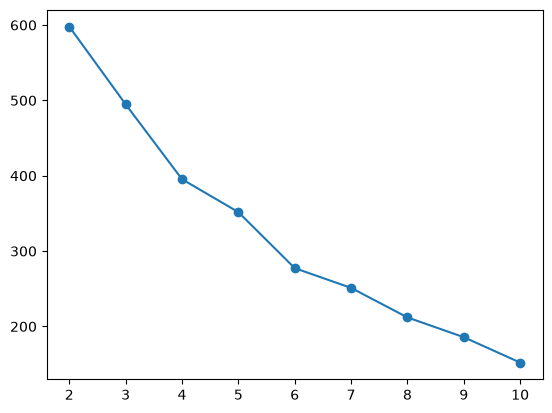

In [16]:
plt.plot(range(2,11),wcss,marker='o')
plt.show()

In [28]:
kmeans=KMeans(n_clusters=6,random_state=42)
kmeans_label=kmeans.fit_predict(x_scaled)

print(f"{silhouette_score(x_scaled,kmeans_label)}")

0.33475434756692174


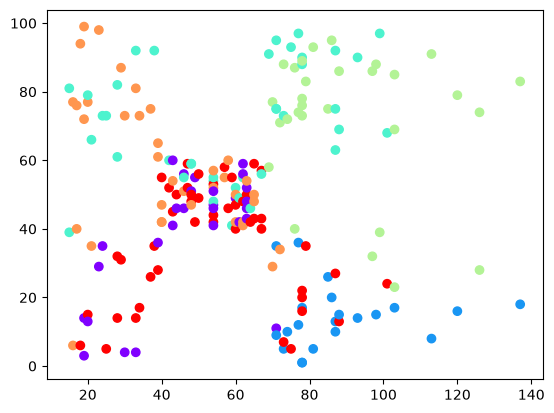

In [23]:
plt.scatter(x['Annual_Income_k'],x['Spending_Score'],c=kmeans_label,cmap='rainbow')
plt.show()

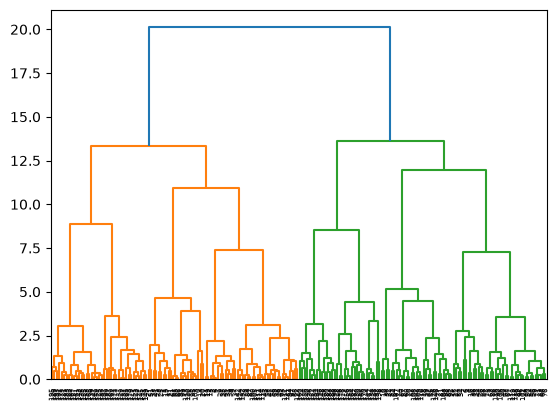

In [25]:
from scipy.cluster.hierarchy import dendrogram,linkage

linked=linkage(x_scaled,method="ward",metric="euclidean")

dendrogram(linked)
plt.show()

In [27]:
hc=AgglomerativeClustering(n_clusters=6)
hc_labels=hc.fit_predict(x_scaled)
print(f"{silhouette_score(x_scaled,hc_labels)}")

0.31024459685260536


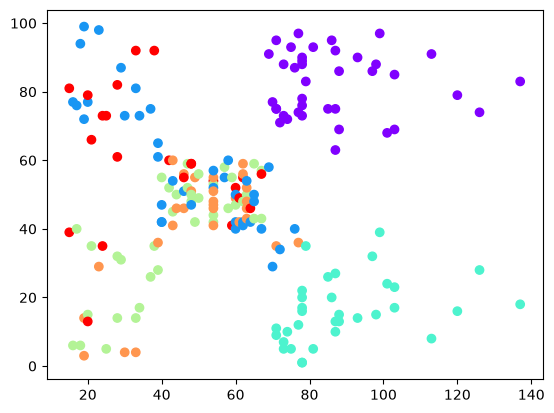

In [30]:
plt.scatter(x['Annual_Income_k'],x['Spending_Score'],c=hc_labels,cmap='rainbow')
plt.show()